In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [4]:
pois = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/delhi_pois.geojson")
wards = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/wards_delhi_c.geojson")

In [5]:
print("POIs:")
display(pois.head())

print("Wards:")
display(wards.head())

print("Number of POIs:", len(pois))
print("Number of wards:", len(wards))

print("POI CRS:", pois.crs)
print("Ward CRS:", wards.crs)

print("POI geometry type:")
print(pois.geometry.geom_type.value_counts())

print("Ward geometry type:")
print(wards.geometry.geom_type.value_counts())

POIs:


,sl_no,PoI_Type,Latitude,Longitude,geometry
0,1,Parks,28.469460,77.122980,POINT (77.12298 28.46946)
1,2,Schools,28.437668,77.141225,POINT (77.14122 28.43767)
2,3,Parks,28.438900,77.142180,POINT (77.14218 28.4389)
3,4,Playgrounds_Open_Source,28.447527,77.138000,POINT (77.138 28.44753)
4,5,amenity,28.452406,77.141672,POINT (77.14167 28.45241)


Wards:


,Ward_Name,Ward_No,geometry
0,DELHI CANTT CHARGE 1,CANT_1,"POLYGON ((77.13228 28.63154, 77.13644 28.62062..."
1,DELHI CANTT CHARGE 2,CANT_2,"POLYGON ((77.15429 28.62335, 77.15501 28.62228..."
2,DELHI CANTT CHARGE 4,CANT_4,"POLYGON ((77.15755 28.57578, 77.15672 28.57564..."
3,DELHI CANTT CHARGE 5,CANT_5,"POLYGON ((77.1348 28.57051, 77.13429 28.57048,..."
4,DELHI CANTT CHARGE 6,CANT_6,"POLYGON ((77.12157 28.59308, 77.12878 28.59029..."


Number of POIs: 50740
Number of wards: 290
POI CRS: EPSG:4326
Ward CRS: EPSG:4326
POI geometry type:
Point    50740
Name: count, dtype: int64
Ward geometry type:
Polygon    290
Name: count, dtype: int64


In [6]:
print(pois.columns)
print(wards.columns)

Index(['sl_no', 'PoI_Type', 'Latitude', 'Longitude', 'geometry'], dtype='str')
Index(['Ward_Name', 'Ward_No', 'geometry'], dtype='str')


In [7]:
pois = pois.rename(columns={
    "sl_no": "id",
    "PoI_Type": "poi_type"
})

wards = wards.rename(columns={
    "OBJECTID": "ward_id",
    "MWARD_NM": "ward_name"
})

display(pois.head())
display(wards.head())

,id,poi_type,Latitude,Longitude,geometry
0,1,Parks,28.469460,77.122980,POINT (77.12298 28.46946)
1,2,Schools,28.437668,77.141225,POINT (77.14122 28.43767)
2,3,Parks,28.438900,77.142180,POINT (77.14218 28.4389)
3,4,Playgrounds_Open_Source,28.447527,77.138000,POINT (77.138 28.44753)
4,5,amenity,28.452406,77.141672,POINT (77.14167 28.45241)


,Ward_Name,Ward_No,geometry
0,DELHI CANTT CHARGE 1,CANT_1,"POLYGON ((77.13228 28.63154, 77.13644 28.62062..."
1,DELHI CANTT CHARGE 2,CANT_2,"POLYGON ((77.15429 28.62335, 77.15501 28.62228..."
2,DELHI CANTT CHARGE 4,CANT_4,"POLYGON ((77.15755 28.57578, 77.15672 28.57564..."
3,DELHI CANTT CHARGE 5,CANT_5,"POLYGON ((77.1348 28.57051, 77.13429 28.57048,..."
4,DELHI CANTT CHARGE 6,CANT_6,"POLYGON ((77.12157 28.59308, 77.12878 28.59029..."


In [8]:
wards = wards.rename(columns={
    "Ward_No": "ward_id",
    "Ward_Name": "ward_name"
})

display(wards.head())

,ward_name,ward_id,geometry
0,DELHI CANTT CHARGE 1,CANT_1,"POLYGON ((77.13228 28.63154, 77.13644 28.62062..."
1,DELHI CANTT CHARGE 2,CANT_2,"POLYGON ((77.15429 28.62335, 77.15501 28.62228..."
2,DELHI CANTT CHARGE 4,CANT_4,"POLYGON ((77.15755 28.57578, 77.15672 28.57564..."
3,DELHI CANTT CHARGE 5,CANT_5,"POLYGON ((77.1348 28.57051, 77.13429 28.57048,..."
4,DELHI CANTT CHARGE 6,CANT_6,"POLYGON ((77.12157 28.59308, 77.12878 28.59029..."


In [9]:
hospital_pois = pois[pois["poi_type"] == "Hospitals"]

display(hospital_pois.head())

,id,poi_type,Latitude,Longitude,geometry
21,22,Hospitals,28.476383,77.129023,POINT (77.12902 28.47638)
96,97,Hospitals,28.463681,77.151760,POINT (77.15176 28.46368)
124,125,Hospitals,28.468912,77.141100,POINT (77.1411 28.46891)
169,170,Hospitals,28.495565,77.141839,POINT (77.14184 28.49556)
225,226,Hospitals,28.513104,77.106843,POINT (77.10684 28.5131)


In [10]:
hospital_joined = gpd.sjoin(
    hospital_pois,
    wards[["ward_id", "ward_name", "geometry"]],
    how="left",
    predicate="within"
)

hospital_joined.head()

,id,poi_type,Latitude,Longitude,geometry,index_right,ward_id,ward_name
21,22,Hospitals,28.476383,77.129023,POINT (77.12902 28.47638),107,175,AYA NAGAR
96,97,Hospitals,28.463681,77.151760,POINT (77.15176 28.46368),107,175,AYA NAGAR
124,125,Hospitals,28.468912,77.141100,POINT (77.1411 28.46891),107,175,AYA NAGAR
169,170,Hospitals,28.495565,77.141839,POINT (77.14184 28.49556),106,174,CHHATARPUR
225,226,Hospitals,28.513104,77.106843,POINT (77.10684 28.5131),247,172,KISHANGARH


In [11]:
hospital_joined[["poi_type", "ward_id", "ward_name"]]

,poi_type,ward_id,ward_name
21,Hospitals,175,AYA NAGAR
96,Hospitals,175,AYA NAGAR
124,Hospitals,175,AYA NAGAR
169,Hospitals,174,CHHATARPUR
225,Hospitals,172,KISHANGARH
...,...,...,...
50409,Hospitals,8,JHARODA
50412,Hospitals,8,JHARODA
50461,Hospitals,265,SHIV VIHAR
50567,Hospitals,271,KARAWAL NAGAR WEST


In [12]:
hospital_joined["ward_id"].isna().sum()

np.int64(2)

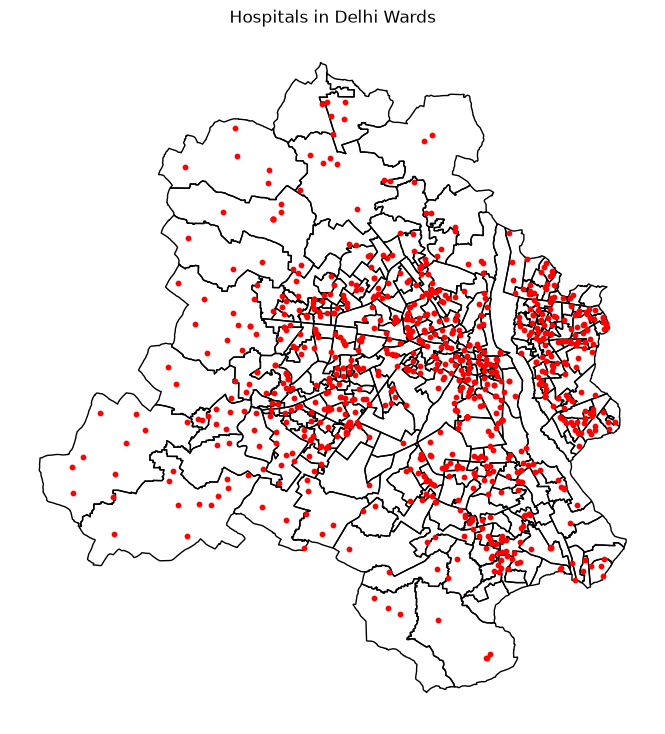

In [13]:
fig, ax = plt.subplots(figsize=(10, 9))

wards.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black"
)

hospital_pois.plot(
    ax=ax,
    color="red",
    markersize=10
)

ax.set_title("Hospitals in Delhi Wards")
ax.set_axis_off()

plt.show()

In [15]:
# Count hospitals in each ward
hospital_counts = (
    hospital_joined
    .groupby("ward_id")
    .size()
    .reset_index(name="hospital_count")
)

# Merge hospital counts with ward boundaries
wards_hospital = wards.merge(
    hospital_counts,
    on="ward_id",
    how="left"
)

# Replace wards with no hospitals by 0
wards_hospital["hospital_count"] = (
    wards_hospital["hospital_count"]
    .fillna(0)
    .astype(int)
)

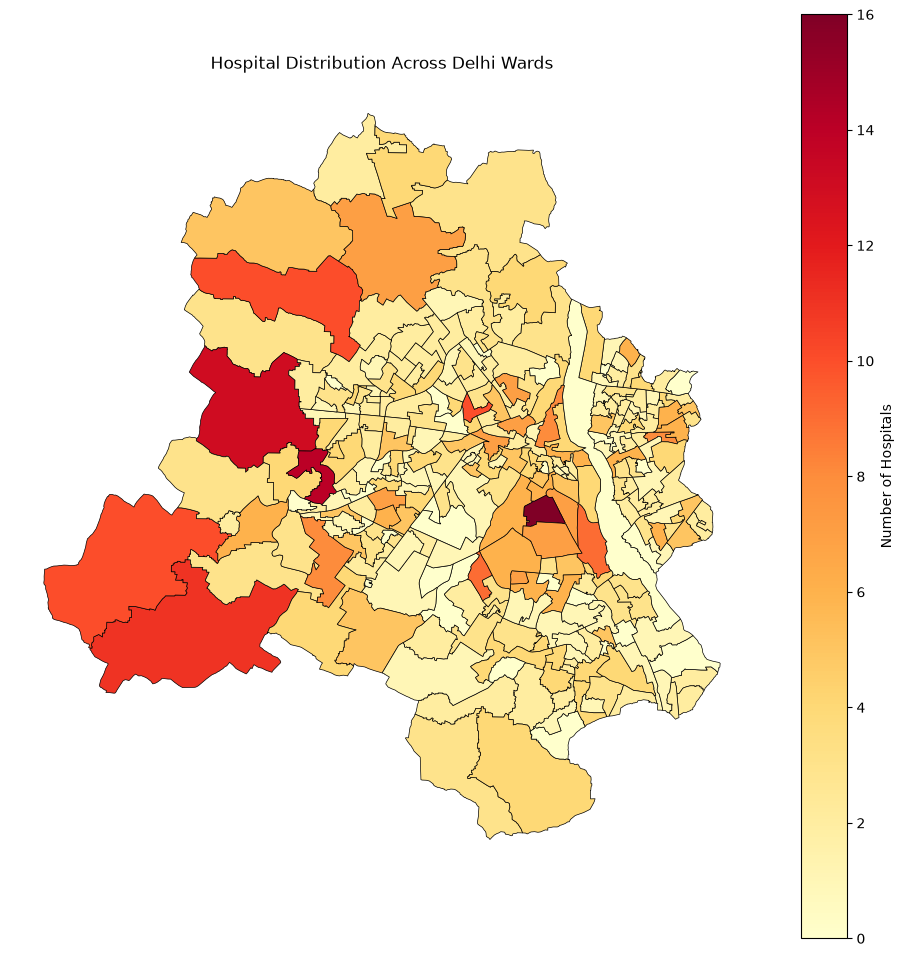

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

wards_hospital.plot(
    column="hospital_count",
    cmap="YlOrRd",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    ax=ax,
    legend_kwds={
        "label": "Number of Hospitals",
        "orientation": "vertical"
    }
)

ax.set_title("Hospital Distribution Across Delhi Wards")
ax.axis("off")

plt.show()